Info    : Meshing 1D...
Info    : [  0%] Meshing curve 1 (Line)
Info    : [ 30%] Meshing curve 2 (Line)
Info    : [ 60%] Meshing curve 3 (Line)
Info    : [ 80%] Meshing curve 4 (Line)
Info    : Done meshing 1D (Wall 8.5982e-05s, CPU 8.1e-05s)
Info    : Meshing 2D...
Info    : Meshing surface 1 (Transfinite)
Info    : Done meshing 2D (Wall 2.1254e-05s, CPU 0s)
Info    : 20 nodes 30 elements


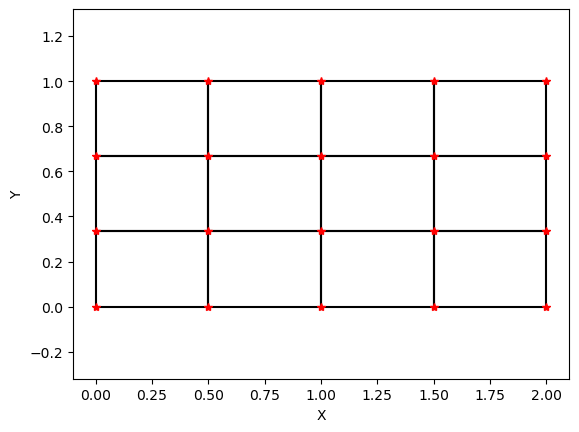

In [6]:
import gmsh
import numpy as np
import matplotlib.pyplot as plt
import sys
class Mesh:
    def __init__(self, dim=1, xmin=0.0, xmax=1.0, ymin=0.0, ymax=1.0, nx=5, ny=5, meshtype='edge2'):
        self.dim = dim
        self.xmin = xmin
        self.xmax = xmax
        self.ymin = ymin
        self.ymax = ymax
        self.nx = nx
        self.ny = ny
        self.meshtype = meshtype
        self.order = 1
        self.nodesperelement = 2
        self.elements = 0
        self.nodes = 0
        self.vtkcelltype = None
        self.nodecoords = None
        self.elementconn = None
        self.bcnodeids = dict()
        self.bcconn = dict()
        self._line_tags = dict()
        self.setmeshtype(meshtype)
    def setnx(self, nx):
        self.nx = nx
    def setny(self, ny):
        self.ny = ny
    def setdomainsize(self, xmin, xmax, ymin=None, ymax=None):
        self.xmin = xmin
        self.xmax = xmax
        if self.dim == 2:
            self.ymin = ymin
            self.ymax = ymax
    def setmeshtype(self, meshtype):
        self.meshtype = meshtype
        if self.dim == 1:
            if 'edge2' in meshtype:
                self.order = 1
                self.nodesperelement = 2
                self.vtkcelltype = 3
            elif 'edge3' in meshtype:
                self.order = 2
                self.nodesperelement = 3
                self.vtkcelltype = 4
            elif 'edge4' in meshtype:
                self.order = 3
                self.nodesperelement = 4
                self.vtkcelltype = 4
            else:
                sys.exit('unsupported 1D mesh type in FEToy!')
        elif self.dim == 2:
            if 'quad4' in meshtype:
                self.order = 1
                self.nodesperelement = 4
                self.vtkcelltype = 9
            elif 'quad9' in meshtype:
                self.order = 2
                self.nodesperelement = 9
                self.vtkcelltype = 28
            else:
                sys.exit('unsupported 2D mesh type in FEToy!')
        else:
            sys.exit("Only dim=1 or dim=2 supported")
    def update(self):
        self.createmesh()
    def createmesh(self):
        gmsh.initialize()
        gmsh.model.add("fetoy_mesh")
        if self.dim == 1:
            self._create_1d_gmsh()
        elif self.dim == 2:
            self._create_2d_gmsh()
        gmsh.finalize()
    def _create_1d_gmsh(self):
        # 1D几何：两点一条线
        p0 = gmsh.model.geo.addPoint(self.xmin, 0, 0)
        p1 = gmsh.model.geo.addPoint(self.xmax, 0, 0)
        line = gmsh.model.geo.addLine(p0, p1)
        self._line_tags["left"] = p0
        self._line_tags["right"] = p1
        self._line_tags["line"] = line
        gmsh.model.geo.synchronize()
        # 结构化网格
        gmsh.model.mesh.setTransfiniteCurve(line, self.nx + 1)
        gmsh.model.mesh.setOrder(self.order)
        gmsh.model.mesh.generate(1)
        # 读取节点
        nodeTags, nodeCoords, _ = gmsh.model.mesh.getNodes()
        nodeCoords = nodeCoords.reshape(-1,3)
        self.nodecoords = nodeCoords[:,0]
        self.nodes = len(nodeTags)
        # 读取单元
        elemTypes, elemTags, elemConn = gmsh.model.mesh.getElements(dim=1)
        conn = np.array(elemConn[0]) - 1
        self.elementconn = conn.reshape(-1, self.nodesperelement)
        self.elements = self.elementconn.shape[0]
        # 边界节点
        def get_node(tag):
            return np.array([tag-1])
        self.bcnodeids = {
            "left": get_node(p0),
            "right": get_node(p1)
        }
        self.bcconn = {}
    def _create_2d_gmsh(self):
        # 矩形4个角点
        p1 = gmsh.model.geo.addPoint(self.xmin, self.ymin, 0)
        p2 = gmsh.model.geo.addPoint(self.xmax, self.ymin, 0)
        p3 = gmsh.model.geo.addPoint(self.xmax, self.ymax, 0)
        p4 = gmsh.model.geo.addPoint(self.xmin, self.ymax, 0)
        l_bottom = gmsh.model.geo.addLine(p1, p2)
        l_right  = gmsh.model.geo.addLine(p2, p3)
        l_top    = gmsh.model.geo.addLine(p3, p4)
        l_left   = gmsh.model.geo.addLine(p4, p1)
        loop = gmsh.model.geo.addCurveLoop([l_bottom, l_right, l_top, l_left])
        surf = gmsh.model.geo.addPlaneSurface([loop])
        gmsh.model.geo.synchronize()
        # 结构化映射四边形网格
        gmsh.model.mesh.setTransfiniteCurve(l_bottom, self.nx+1)
        gmsh.model.mesh.setTransfiniteCurve(l_right, self.ny+1)
        gmsh.model.mesh.setTransfiniteCurve(l_top, self.nx+1)
        gmsh.model.mesh.setTransfiniteCurve(l_left, self.ny+1)
        gmsh.model.mesh.setTransfiniteSurface(surf)
        gmsh.model.mesh.setRecombine(2, surf)
        gmsh.model.mesh.setOrder(self.order)
        gmsh.model.mesh.generate(2)
        # 读取节点坐标
        nodeTags, nodeCoords, _ = gmsh.model.mesh.getNodes()
        nodeCoords = nodeCoords.reshape(-1,3)
        self.nodecoords = nodeCoords[:,:2]
        self.nodes = len(nodeTags)
        # 单元连通
        elemTypes, elemTags, elemConn = gmsh.model.mesh.getElements(dim=2)
        conn = np.array(elemConn[0]) - 1
        self.elementconn = conn.reshape(-1, self.nodesperelement)
        self.elements = self.elementconn.shape[0]
        # 提取边界节点
        def get_nodes_on_curve(curve_tag):
            nt, _, _ = gmsh.model.mesh.getNodes(1, curve_tag)
            return np.array(nt)-1
        self.bcnodeids = {
            "bottom": get_nodes_on_curve(l_bottom),
            "right": get_nodes_on_curve(l_right),
            "top": get_nodes_on_curve(l_top),
            "left": get_nodes_on_curve(l_left)
        }
        self._line_tags = {"bottom":l_bottom,"right":l_right,"top":l_top,"left":l_left}
        # ===== 修复：按阶数自动确定边单元节点数量 =====
        def get_elem_on_curve(curve_tag):
            etype, etags, econn = gmsh.model.mesh.getElements(1, curve_tag)
            c = np.array(econn[0]) -1
            n_edge_node = self.order + 1
            return c.reshape(-1, n_edge_node)
        self.bcconn = {
            "bottom": get_elem_on_curve(l_bottom),
            "right": get_elem_on_curve(l_right),
            "top": get_elem_on_curve(l_top),
            "left": get_elem_on_curve(l_left)
        }
    def printnodes(self):
        print(f'*** node coordinates (total nodes={self.nodes}, nodes per element={self.nodesperelement})')
        for i in range(self.nodes):
            if self.dim ==1:
                print(f'{i+1:6d}-th node: x={self.nodecoords[i]:14.6e}')
            else:
                print(f'{i+1:6d}-th node: x={self.nodecoords[i,0]:14.6e}, y={self.nodecoords[i,1]:14.6e}')
    def printelements(self):
        print(f'*** element connectivity (bulk elements={self.elements})')
        for e in range(self.elements):
            s = f'{e+1:6d}-th element :'
            for val in self.elementconn[e,:]:
                s += f'{val:5d} '
            print(s)
    def plotmesh(self, withnode=False, withnodeid=False):
        plt.figure()
        if self.dim ==1:
            y = np.zeros_like(self.nodecoords)
            plt.plot(self.nodecoords, y, 'k')
            if withnode:
                plt.plot(self.nodecoords, y, 'r*')
            if withnodeid:
                for i,x in enumerate(self.nodecoords):
                    plt.text(x,0.0,f'{i+1}')
            plt.xlabel('X')
            plt.ylabel('Y')
        else:
            for e in range(self.elements):
                conn = self.elementconn[e,:].copy()
                if self.meshtype == "quad4":
                    conn = np.append(conn, conn[0])
                elif self.meshtype == "quad9":
                    conn = np.array([conn[0],conn[4],conn[1],conn[5],conn[2],conn[6],conn[3],conn[7],conn[0]])
                x = self.nodecoords[conn,0]
                y = self.nodecoords[conn,1]
                plt.plot(x,y,'k')
            if withnode:
                plt.plot(self.nodecoords[:,0], self.nodecoords[:,1],'r*')
            if withnodeid:
                for i in range(self.nodes):
                    x,y = self.nodecoords[i]
                    plt.text(x,y,f'{i+1}')
            plt.xlabel('X')
            plt.ylabel('Y')
            plt.axis("equal")
        plt.grid(False)
        plt.show()

# 你的测试代码
mesh2 = Mesh(dim=2, xmin=0,xmax=2,ymin=0,ymax=1, nx=4, ny=3, meshtype="quad4")
mesh2.createmesh()
mesh2.plotmesh(withnode=True)


Info    : Meshing 1D...
Info    : Meshing curve 1 (Line)
Info    : Done meshing 1D (Wall 5.2695e-05s, CPU 0s)
Info    : 6 nodes 7 elements


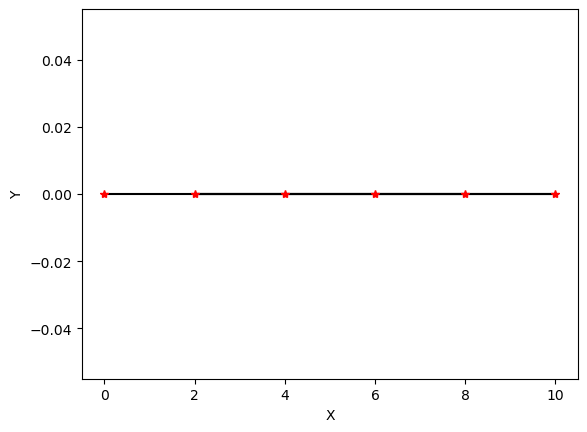

In [7]:
mesh1d = Mesh(dim=1, xmin=0, xmax=10, nx=5, meshtype="edge2")
mesh1d.createmesh()
mesh1d.plotmesh(withnode=True)

Info    : Meshing 1D...
Info    : [  0%] Meshing curve 1 (Line)
Info    : [ 30%] Meshing curve 2 (Line)
Info    : [ 60%] Meshing curve 3 (Line)
Info    : [ 80%] Meshing curve 4 (Line)
Info    : Done meshing 1D (Wall 0.000123922s, CPU 0.000199s)
Info    : Meshing 2D...
Info    : Meshing surface 1 (Transfinite)
Info    : Done meshing 2D (Wall 2.5977e-05s, CPU 2.2e-05s)
Info    : 20 nodes 30 elements


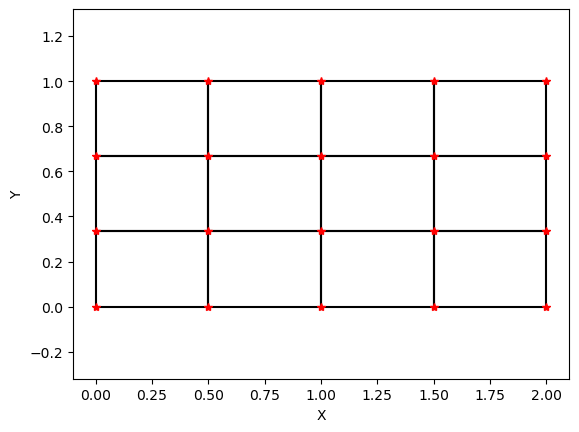

In [8]:
#2D quad4
mesh2 = Mesh(dim=2, xmin=0,xmax=2,ymin=0,ymax=1, nx=4, ny=3, meshtype="quad4")
mesh2.createmesh()
mesh2.plotmesh(withnode=True)

In [5]:
import gmsh
print(gmsh.__version__)

4.15.2


In [9]:
__author__="Peng Lin"
__copyright__= "Copyright"
__version__ = "1.0"
__maintainer__ = "Peng Lin"
__email__ = "15940208197@163.com"
__status__ = "development"
__date__ = "Octo 1, 2026"


import numpy as np
import matplotlib.pyplot as plt
import sys

class gausspoint1d:
    def __init__(self,ngp=1):
        """
        Initialize the gauss point class

        Parameters
        ----------
        ngp : int
            the number of gauss points
        """
        self.ngp=ngp
        self.gpcoords=np.zeros((ngp,2)) # 0-> weight, 1-> xi

    def setnum(self,num):
        """
        Set up the gauss point number

        Parameters
        ----------
        num : int
            the number of gauss point one want to generate
        """
        self.ngp=num
    def getgausspointsnumber(self):
        """
        Get the number of gauss points
        """
        return self.ngp
    def creategausspoint(self):
        """
        Generate the gauss points 
        """
        self.gpcoords=np.zeros((self.ngp,2))
        if self.ngp==1:
            self.gpcoords[0,0]=2.0
            self.gpcoords[0,1]=0.0
        elif self.ngp==2:
            self.gpcoords[0,0]=1.0
            self.gpcoords[0,1]=-np.sqrt(1.0/3.0)

            self.gpcoords[1,0]=1.0
            self.gpcoords[1,1]= np.sqrt(1.0/3.0)
        elif self.ngp==3:
            self.gpcoords[0,0]=5.0/9.0
            self.gpcoords[0,1]=-np.sqrt(3.0/5.0)

            self.gpcoords[1,0]=8.0/9.0
            self.gpcoords[1,1]= 0.0

            self.gpcoords[2,0]=5.0/9.0
            self.gpcoords[2,1]= np.sqrt(3.0/5.0)
        elif self.ngp==4:
            t=np.sqrt(4.8)
            w=1.0/3.0/t

            self.gpcoords[0,1]=-np.sqrt((3.0+t)/7.0)
            self.gpcoords[1,1]=-np.sqrt((3.0-t)/7.0)
            self.gpcoords[2,1]= np.sqrt((3.0-t)/7.0)
            self.gpcoords[3,1]= np.sqrt((3.0+t)/7.0)

            self.gpcoords[0,0]=0.5-w
            self.gpcoords[1,0]=0.5+w
            self.gpcoords[2,0]=0.5+w
            self.gpcoords[3,0]=0.5-w
        elif self.ngp==5:
            t=np.sqrt(1120.0)
            self.gpcoords[1-1, 1] = -np.sqrt((70.0 + t) / 126.0)
            self.gpcoords[2-1, 1] = -np.sqrt((70.0 - t) / 126.0)
            self.gpcoords[3-1, 1] = 0.0
            self.gpcoords[4-1, 1] = np.sqrt((70.0 - t) / 126.0)
            self.gpcoords[5-1, 1] = np.sqrt((70.0 + t) / 126.0)
     
            self.gpcoords[1-1, 0] = (21.0 * t + 117.60) / (t * (70.0 + t))
            self.gpcoords[2-1, 0] = (21.0 * t - 117.60) / (t * (70.0 - t))
            self.gpcoords[3-1, 0] = 2.0 * (1.0 - self.gpcoords[1-1, 0] -self.gpcoords[2-1, 0])
            self.gpcoords[4-1, 0] = self.gpcoords[2-1, 0]
            self.gpcoords[5-1, 0] = self.gpcoords[1-1, 0]
        else:
            sys.exit("unsuported gauss point number in 1d case")
    def update(self):
        """
        Update/re-generate the gauss point number
        """
        self.creategausspoint()
    def print(self):
        for i in range(self.ngp):
            str='%d-th gauss point: xi=%14.5e, weight=%14.5e'%(i+1,self.gpcoords[i,1],self.gpcoords[i,0])
            print(str)
    def getIthweight(self,i):
        """
        Get the i-th gauss point's weight

        Parameters
        ----------
        i : int
            the i-th gauss point
        """
        if i>self.ngp:
            sys.exit('%d is out of 1d gauss points range !'%(i))
        return self.gpcoords[i,0]
    def getIthcoord(self,i):
        """
        Get the i-th gauss point's coordinate
        """
        if i>self.ngp:
            sys.exit('%d is out of 1d gauss points range !'%(i))
        return self.gpcoords[i,1]
    def plot(self):
        plt.figure()
        plt.plot(self.gpcoords[:,1],self.gpcoords[:,0],'k*')
        plt.xlabel(r'$\xi$',fontsize=16)
        plt.ylabel(r'$w$',fontsize=16)
        plt.xticks(fontsize=12)
        plt.yticks(fontsize=12)
###########################################################################
class gausspoint2d:
    def __init__(self,ngp):
        """
        Initialize the 2d gauss points
        """
        self.ngp=ngp
        self.ngp2=ngp*ngp
        self.gpcoords=np.zeros((self.ngp2,3)) # 0->weight,1->xi,2->eta
    def setnum(self,ngp):
        """
        Get the i-th gauss point's weight

        Parameters
        ----------
        ngp : int
            the number of gauss point in each direction
        """
        self.ngp=ngp
        self.ngp2=ngp*ngp
        if ngp>5:
            sys.exit("unsupported gauss points number in 2d case!")
    def creategausspoint(self):
        """
        Generate the 2d gauss points
        """
        if self.ngp>5:
            sys.exit('can not generate 2d gauss point, unsupported gauss point number (must <=5) !!!')
        self.gpcoords=np.zeros((self.ngp2,3))
        gp1d=gausspoint1d(self.ngp)
        gp1d.creategausspoint()
        k=0
        for i in range(self.ngp):
            for j in range(self.ngp):
                self.gpcoords[k,0]=gp1d.gpcoords[i,0]*gp1d.gpcoords[j,0]
                self.gpcoords[k,1]=gp1d.gpcoords[i,1]
                self.gpcoords[k,2]=gp1d.gpcoords[j,1]
                k+=1
    def print(self):
        for i in range(self.ngp2):
            str='%d-th gauss point: xi=%14.5e, eta=%14.5e, weight=%14.5e'%(i+1,self.gpcoords[i,1],self.gpcoords[i,2],self.gpcoords[i,0])
            print(str)
    def update(self):
        """
        Update the gauss points 
        """
        self.creategausspoint()
    def getgausspointsnumber(self):
        return self.ngp2
    def getIthcoords(self,i):
        """
        get the i-th gauss point's coordinate

        Parameters
        ----------
        i : int
            the node index
        """
        if i>self.ngp2:
            sys.exit('i=%d is out of 2d gauss point range'%(i))
        return self.gpcoords[i,1],self.gpcoords[i,2]
    def getIthweight(self,i):
        """
        get the i-th gauss point's weight
        Parameters
        ----------
        i : int
            the gauss point index (0-based)
        """
        if i >= self.ngp2:
            sys.exit('i=%d is out of 2d gauss point range'%(i))
        return self.gpcoords[i,0]
    def plot(self):
        fig=plt.figure()
        plt.clf()
        ax=fig.add_subplot(projection='3d')
        ax.scatter(self.gpcoords[:,1],self.gpcoords[:,2],self.gpcoords[:,0])
        ax.set_xlabel(r'$\xi$',fontsize=14)
        ax.set_ylabel(r'$\eta$',fontsize=14)
        ax.set_zlabel(r'$w$',fontsize=14)

In [10]:
gp2d = gausspoint2d(ngp=2)
gp2d.creategausspoint()
gp2d.print()

1-th gauss point: xi=  -5.77350e-01, eta=  -5.77350e-01, weight=   1.00000e+00
2-th gauss point: xi=  -5.77350e-01, eta=   5.77350e-01, weight=   1.00000e+00
3-th gauss point: xi=   5.77350e-01, eta=  -5.77350e-01, weight=   1.00000e+00
4-th gauss point: xi=   5.77350e-01, eta=   5.77350e-01, weight=   1.00000e+00
